# Training the Yoruba Acoustic Model

This notebook trains the MFA acoustic model that Stage 3 of the pronunciation
engine depends on. **It is the only training step the project requires.**

## Why this is necessary

MFA aligns audio to text using a pretrained acoustic model. Yoruba is not
reliably among the languages it ships, and multilingual substitutes degrade on
exactly what matters here: vowel boundaries. A boundary 30 ms out pulls F0 from a
neighbouring consonant transition and produces a tone error that is not real.

## What kind of training this is

Not deep learning. MFA's trainer is a **GMM-HMM pipeline on Kaldi**:

- **CPU only.** No GPU.
- **Hours, not days.**
- **Self-supervised on your own data** — audio plus transcripts, both of which
  you already have. No manual phone labelling.
- Output is one `.zip`, tens of MB.

It bootstraps: flat start, monophone, realign, triphone, realign, LDA+MLLT, SAT.
Each pass sharpens the boundaries the previous one produced.

## This corpus

Measured by the audit below:

| | |
|---|---|
| Utterances | 3,583 |
| Audio | 4.03 hours, 48 kHz mono WAV |
| Speakers | 36 (19 female, 17 male) |
| Vocabulary | 3,413 words |
| Tone-mark coverage | **100%** |

Two sources were downloaded. Only one is usable as a tone reference:

**`yo_ng_female` + `yo_ng_male`** (OpenSLR layout) — fully diacritized. This is
the corpus used below.

**`Yoruba-TTS-Dataset`** — 1,949 MP3 clips whose transcripts carry **no tone
marks at all**. Unusable as a tone reference: every vowel would read as Mid. It
can still contribute audio to acoustic training, but only with tone-stripped
phones, and it is off by default. See the `--include-tts` flag in section 1.

## Time budget

At 4 hours of audio and 7 parallel jobs, expect **roughly 1 to 2 hours** for the
full train. Monophone finishes in minutes; SAT dominates.

## Prerequisites

Everything below is already installed on this machine:

- **Run this notebook from `/home/seqaeon/Downloads/venv`.** The engine is
  installed there editable, along with Parselmouth, matplotlib and Jupyter.
- MFA 3.4.1 lives in `.mfa-env/` in the project root. **You do not need to
  activate it.** The engine invokes `mfa` as a subprocess and prepends its `bin`
  directory to `PATH` automatically — which is required, because MFA shells out
  to OpenFST tools like `fstcompile` that sit beside the binary.

---
## 1. Prepare the corpus

`scripts/prepare_dataset.py` merges the downloaded sources into the layout the
engine expects: `data/corpus/line_index.tsv` plus `data/corpus/wavs/`. Audio is
**symlinked**, not copied, so this costs no extra disk.

Re-running is safe; already-staged files are skipped.

In [1]:
import os
import shutil
import subprocess
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

# Add --include-tts to also stage the undiacritized MP3 dataset. Only do that
# with TONE_IN_PHONES = False below, or its all-Mid vowels will corrupt the
# tone-conditioned phone models.
result = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "prepare_dataset.py")],
    capture_output=True, text=True,
)
print(result.stdout or result.stderr)

Scanning sources:
  yo_ng_female: 1892 utterances, 19 speakers, 100.0% tone-marked
  yo_ng_male: 1691 utterances, 17 speakers, 100.0% tone-marked

Total: 3583 utterances, 36 speakers, 100.0% tone-marked

Staging into /home/seqaeon/Downloads/Yoruba_Learner/data/corpus/wavs ...

Staged 0 symlinks
Wrote /home/seqaeon/Downloads/Yoruba_Learner/data/corpus/line_index.tsv

Next: yoruba-engine audit



---
## 2. Environment check

The engine resolves `mfa` in this order: `$MFA_BIN`, then the project-local
`.mfa-env/bin/mfa`, then `PATH`. Activating a conda environment is not required.

In [2]:
from yoruba_engine.config import EngineConfig

config = EngineConfig()
MFA_BIN = config.mfa.executable

if shutil.which(MFA_BIN) is None and not Path(MFA_BIN).exists():
    raise RuntimeError(
        f"mfa not found at {MFA_BIN!r}.\n\n"
        "Install it with:\n"
        "  micromamba create -y -p .mfa-env -c conda-forge python=3.11 "
        "montreal-forced-aligner\n"
        "See INSTALL.md."
    )

version = subprocess.run([MFA_BIN, "version"], capture_output=True, text=True).stdout.strip()
print(f"MFA     : {version}  ({MFA_BIN})")
print(f"Python  : {sys.version.split()[0]}")
print(f"Project : {PROJECT_ROOT}")

MFA     : 3.4.1  (/home/seqaeon/Downloads/Yoruba_Learner/.mfa-env/bin/mfa)
Python  : 3.12.3
Project : /home/seqaeon/Downloads/Yoruba_Learner


In [3]:
import logging

from yoruba_engine.logging_utils import configure_logging

configure_logging(level=logging.INFO)

config.corpus_dir = PROJECT_ROOT / "data" / "corpus"
config.line_index = config.corpus_dir / "line_index.tsv"
config.audio_dir = config.corpus_dir / "wavs"
config.output_dir = PROJECT_ROOT / "output"

MFA_CORPUS = PROJECT_ROOT / "data" / "mfa_corpus"
MODEL_DIR = PROJECT_ROOT / "models"
ALIGN_DIR = PROJECT_ROOT / "output" / "aligned"
DICT_PATH = PROJECT_ROOT / "data" / "dictionary" / "yoruba.dict"
OVERRIDES_PATH = PROJECT_ROOT / "data" / "dictionary" / "overrides.tsv"

for directory in (MODEL_DIR, ALIGN_DIR, config.output_dir):
    directory.mkdir(parents=True, exist_ok=True)

NUM_JOBS = max(1, (os.cpu_count() or 4) - 1)
print(f"Corpus   : {config.corpus_dir}")
print(f"Parallel : {NUM_JOBS} jobs")

Corpus   : /home/seqaeon/Downloads/Yoruba_Learner/data/corpus
Parallel : 15 jobs


---
## 3. Audit

Three findings here can stop the project before any time is spent training:

1. **Low diacritic coverage** — no tone marks means no tone comparison, ever.
2. **Too little audio** — under ~3 hours, train speaker-adapted instead.
3. **Missing audio** — transcripts without recordings must be excluded.

In [4]:
from yoruba_engine.audit.dataset_audit import DatasetAuditor

auditor = DatasetAuditor(config)
report = auditor.audit()
paths = auditor.write_all(report)

print(f"\n{'Matched utterances':<24}: {len(report.matched)}")
print(f"{'Total audio':<24}: {report.total_duration_hours:.2f} hours")
print(f"{'Unique words':<24}: {len(report.word_frequency)}")
print(f"{'Speakers':<24}: {len(report.speakers)}")
print(f"{'Tone-mark coverage':<24}: {report.tone_mark_coverage * 100:.1f}%")
print(f"{'Non-speech markers':<24}: {report.noise_tokens}")
print(f"{'Missing audio':<24}: {len(report.missing_audio)}")

2026-08-13 22:29:56,437 | INFO     | yoruba_engine.audit | Audited 3583 lines: 3583 matched, 0 missing audio, 0 unreadable
2026-08-13 22:29:56,438 | INFO     | yoruba_engine.audit | Total audio: 4.03 hours across 36 speakers; vocabulary 3412 words
2026-08-13 22:29:56,439 | INFO     | yoruba_engine.audit | Wrote /home/seqaeon/Downloads/Yoruba_Learner/output/dataset_report.txt
2026-08-13 22:29:56,443 | INFO     | yoruba_engine.audit | Wrote 3412 words to /home/seqaeon/Downloads/Yoruba_Learner/output/vocabulary.txt
2026-08-13 22:29:56,450 | INFO     | yoruba_engine.audit | Wrote /home/seqaeon/Downloads/Yoruba_Learner/output/word_frequency.csv
2026-08-13 22:29:56,451 | INFO     | yoruba_engine.audit | Wrote 0 missing-audio rows to /home/seqaeon/Downloads/Yoruba_Learner/output/missing_audio.csv



Matched utterances      : 3583
Total audio             : 4.03 hours
Unique words            : 3412
Speakers                : 36
Tone-mark coverage      : 100.0%
Non-speech markers      : 1307
Missing audio           : 0


In [5]:
# --- Go / no-go gate -------------------------------------------------------
problems = []

if report.tone_mark_coverage < 0.5:
    problems.append(
        f"BLOCKER: only {report.tone_mark_coverage:.0%} of transcripts carry tone "
        "marks. Tone comparison cannot work on this corpus."
    )

if report.total_duration_hours < 3.0:
    problems.append(
        f"WARNING: {report.total_duration_hours:.2f} h is below the ~3 h floor for a "
        "speaker-independent model. Set SPEAKER_ADAPTED = True below."
    )

if len(report.matched) < 500:
    problems.append(
        f"WARNING: only {len(report.matched)} utterances; triphone models may be "
        "under-trained."
    )

for problem in problems:
    print(problem, "\n")
if not problems:
    print("Corpus is adequate for speaker-independent acoustic model training.")

Corpus is adequate for speaker-independent acoustic model training.


### Non-speech annotations

These transcripts annotate non-speech events inline:

| Marker | Count |
|---|---|
| `[snap]` | 700 |
| `[breath]` | 395 |
| `[external]` | 192 |
| `[abrupt]` | 16 |
| `[hesitation]` | 4 |

The engine collapses all of them to a single `[noise]` token mapped to MFA's
`spn` (spoken noise) phone. They are deliberately **not** deleted: if the aligner
does not know a snap occupies that stretch of audio, it stretches the
neighbouring vowel across it, and that vowel's F0 measurement — the thing tone
detection reads — is then wrong.

They are excluded from the vocabulary, and the comparison stage drops them before
scoring, so a learner is never penalized for not reproducing the reference
speaker's breathing.

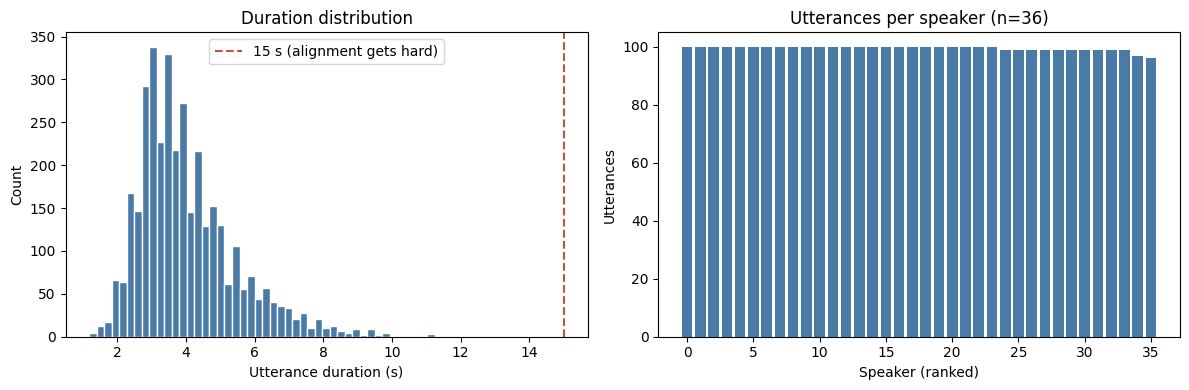

0 utterances over 15 s -- these often fail to align.


In [6]:
import matplotlib.pyplot as plt

durations = [u.duration_s for u in report.matched if u.duration_s]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(durations, bins=50, color="#4a7ba7", edgecolor="white")
ax1.set_xlabel("Utterance duration (s)")
ax1.set_ylabel("Count")
ax1.set_title("Duration distribution")
ax1.axvline(15, color="#c1553b", linestyle="--", label="15 s (alignment gets hard)")
ax1.legend()

counts = sorted(report.speakers.values(), reverse=True)
ax2.bar(range(len(counts)), counts, color="#4a7ba7")
ax2.set_xlabel("Speaker (ranked)")
ax2.set_ylabel("Utterances")
ax2.set_title(f"Utterances per speaker (n={len(counts)})")

plt.tight_layout()
plt.show()

long_utterances = [u for u in report.matched if u.duration_s and u.duration_s > 15]
print(f"{len(long_utterances)} utterances over 15 s -- these often fail to align.")

---
## 4. Build the pronunciation dictionary

Rule-based; takes seconds.

### Design decision: tone-suffixed or tone-stripped phones?

The most consequential choice in this notebook.

**Tone-suffixed** (`a_H`/`a_M`/`a_L`) lets the model learn tone-conditioned vowel
realizations and yields sharper boundaries — but triples the vowel inventory, so
each phone gets a third as much data.

**Tone-stripped** (`a` only) trains reliably on a small corpus.

| Corpus | Recommendation |
|---|---|
| Under 5 h | Tone-stripped |
| 5–20 h | Try both |
| Over 20 h | Tone-suffixed |

**At 4.03 hours this corpus selects tone-stripped automatically.** That costs
nothing in tone accuracy: Stage 5 measures tone from the pitch contour, not from
phone labels. It only gives up some boundary sharpness.

In [7]:
TONE_IN_PHONES = report.total_duration_hours >= 5.0
print(f"{report.total_duration_hours:.2f} h -> TONE_IN_PHONES = {TONE_IN_PHONES}")
print("Set it manually to compare both.")

4.03 h -> TONE_IN_PHONES = False
Set it manually to compare both.


In [8]:
import re

from yoruba_engine.g2p.dictionary import PronunciationDictionary

dictionary = PronunciationDictionary.load_overrides(OVERRIDES_PATH)
dictionary.build(report.vocabulary)

if not TONE_IN_PHONES:
    stripped = {}
    for word, variants in dictionary.entries.items():
        new_variants = []
        for variant in variants:
            phones = " ".join(re.sub(r"_[HML]$", "", p) for p in variant.split())
            if phones not in new_variants:
                new_variants.append(phones)
        stripped[word] = new_variants
    dictionary.entries = stripped

dictionary.write(DICT_PATH)
dictionary.write_failures(config.output_dir / "g2p_failures.csv")

inventory = sorted(dictionary.phone_inventory())
print(f"\nEntries        : {len(dictionary.entries)}")
print(f"Phone inventory: {len(inventory)}")
print(f"Phones         : {' '.join(inventory)}")
print(f"G2P failures   : {len(dictionary.failures)}")

2026-08-13 22:30:02,606 | INFO     | yoruba_engine.g2p | Loaded 12 manual overrides from /home/seqaeon/Downloads/Yoruba_Learner/data/dictionary/overrides.tsv
2026-08-13 22:30:02,716 | INFO     | yoruba_engine.g2p | Built dictionary: 3413 entries, 0 failures
2026-08-13 22:30:02,735 | INFO     | yoruba_engine.g2p | Wrote 3413 dictionary entries to /home/seqaeon/Downloads/Yoruba_Learner/data/dictionary/yoruba.dict
2026-08-13 22:30:02,736 | INFO     | yoruba_engine.g2p | Wrote 0 G2P failures to /home/seqaeon/Downloads/Yoruba_Learner/output/g2p_failures.csv



Entries        : 3413
Phone inventory: 33
Phones         : E En O On S a an b d e en f g gb h i in j k l m n o on p r s spn t u un w y
G2P failures   : 0


The G2P handles three orthographic conditions found in these transcripts, so they
do not need manual overrides:

- **Elision apostrophes** (`l'órí` = `ní` + `orí`). The corpus uses U+2019, U+2018
  and ASCII interchangeably; all are folded to one form. This alone accounted for
  roughly 200 of the 230 words that initially failed conversion.
- **Misplaced dots below** (`j̣`, `ṛ`, `ạ`). Only `e`, `o`, `s` take a dot in
  Yoruba; elsewhere it is a typo and is discarded rather than failing the word.
- **Orphan combining marks** — a tone mark typed before its letter.

What remains are genuine foreign proper nouns, listed in `overrides.tsv`.
**Those pronunciations are a best guess and you should verify them** against the
recordings — a wrong entry corrupts that word's alignment.

In [9]:
if dictionary.failures:
    print(f"{len(dictionary.failures)} words could not be converted:\n")
    for word, reason in list(dictionary.failures.items())[:20]:
        print(f"  {word:<25} (x{report.word_frequency[word]:<4}) {reason[:60]}")
    print(f"\nAdd overrides to {OVERRIDES_PATH}, then re-run the cell above.")
else:
    print("No G2P failures. Every word in the vocabulary was converted.")

No G2P failures. Every word in the vocabulary was converted.


In [10]:
# Phone coverage. Phones seen only a few times will be poorly trained.
from collections import Counter

from yoruba_engine.g2p.orthography import tokenize

phone_counts = Counter()
for utterance in report.matched:
    for token in tokenize(utterance.transcript):
        for variant in dictionary.entries.get(token, [])[:1]:
            phone_counts.update(variant.split())

rare = {p: c for p, c in phone_counts.items() if c < 50}
print(f"Phones observed   : {len(phone_counts)}")
print(f"Rare phones (<50) : {len(rare)}")
for phone, count in sorted(rare.items(), key=lambda kv: kv[1]):
    print(f"  {phone:<10} {count}")
if len(rare) > 8:
    print("\nMany rare phones. Set TONE_IN_PHONES = False and rebuild.")

Phones observed   : 33
Rare phones (<50) : 1
  en         10


---
## 5. Stage the corpus in MFA layout

MFA wants paired audio and `.lab` files grouped into per-speaker directories.
Speaker grouping matters: SAT estimates a per-speaker transform and needs to know
which utterances belong together.

This copies the audio (MFA does not follow symlinks reliably), so expect about
1.3 GB.

In [11]:
from yoruba_engine.alignment.mfa import MFAAligner

if MFA_CORPUS.exists():
    shutil.rmtree(MFA_CORPUS)

MFAAligner.prepare_corpus(report.matched, MFA_CORPUS, by_speaker=True)

staged_audio = list(MFA_CORPUS.rglob("*.wav"))
staged_labs = list(MFA_CORPUS.rglob("*.lab"))
speaker_dirs = [d for d in MFA_CORPUS.iterdir() if d.is_dir()]
print(f"Staged {len(staged_audio)} audio files, {len(staged_labs)} transcripts, "
      f"{len(speaker_dirs)} speaker directories")

2026-08-13 18:25:57,009 | INFO     | yoruba_engine.mfa | Prepared MFA corpus with 3583 utterances at /home/seqaeon/Downloads/Yoruba_Learner/data/mfa_corpus


Staged 3583 audio files, 3583 transcripts, 36 speaker directories


---
## 6. Validate

`mfa validate` checks that every transcript word is in the dictionary and every
audio file is readable. **Out-of-vocabulary words are the most common cause of
training failure** — resolve them here, not an hour into a run.

Note this runs `validate` without an acoustic model, which is the correct form
before one exists.

In [11]:
import re
import time

# Rich redraws its progress bar ~10x/second. Through a pipe every redraw arrives
# as a fresh line instead of overwriting, which floods the notebook. Drop those
# lines and print our own heartbeat instead.
_PROGRESS = re.compile(r"[━╸]|\d+%\s|it/s|\?\s*it")


def run_mfa(args, description="", heartbeat_s=30):
    'Run an MFA subcommand, streaming output with progress bars filtered out.'
    command = [str(MFA_BIN), *[str(a) for a in args]]

    # MFA shells out to OpenFST/Kaldi binaries (fstcompile, gmm-align-compiled)
    # that live beside the mfa executable, so its bin directory must be on PATH.
    env = os.environ.copy()
    bin_dir = Path(MFA_BIN).resolve().parent
    env["PATH"] = f"{bin_dir}{os.pathsep}{env.get('PATH', '')}"
    env["TERM"] = "dumb"
    env["NO_COLOR"] = "1"

    if description:
        print(f"=== {description} ===")
    print(" ".join(command), "\n", flush=True)

    started = time.time()
    last_beat = started
    suppressed = 0
    lines = []

    process = subprocess.Popen(
        command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, env=env,
    )
    for line in process.stdout:
        lines.append(line)

        if _PROGRESS.search(line):
            suppressed += 1
            now = time.time()
            if now - last_beat >= heartbeat_s:
                mins = (now - started) / 60
                print(f"  ... running {mins:.1f} min ({suppressed} progress lines hidden)",
                      flush=True)
                last_beat = now
            continue

        if line.strip():
            print(line, end="", flush=True)

    process.wait()
    print(f"\nFinished in {(time.time() - started) / 60:.1f} min "
          f"(exit {process.returncode}, {suppressed} progress lines hidden)")

    if process.returncode != 0:
        # Show the tail of the real output so the failure is diagnosable.
        tail = [ln for ln in lines if not _PROGRESS.search(ln)][-25:]
        print("\n--- last output before failure ---")
        print("".join(tail))
        raise RuntimeError(f"MFA exited {process.returncode}")

    return "".join(lines)


In [12]:
validation_output = run_mfa(
    ["validate", MFA_CORPUS, DICT_PATH, "--num_jobs", NUM_JOBS, "--clean"],
    "Corpus validation",
)

=== Corpus validation ===
/home/seqaeon/Downloads/Yoruba_Learner/.mfa-env/bin/mfa validate /home/seqaeon/Downloads/Yoruba_Learner/data/mfa_corpus /home/seqaeon/Downloads/Yoruba_Learner/data/dictionary/yoruba.dict --num_jobs 15 --clean 

 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
 INFO     Found 36 speakers across 3583 files, average number of utterances per 
          speaker: 99.52777777777777                                            
 INFO     Initializing multiprocessing jobs...                                  
 INFO     Normalizing text...                                                   
 INFO     Generating MFCCs...                                                   
 INFO     Calculating CMVN...                                                   
 INFO     Generating final features...                                          
 INFO     Creating corpus split...

In [13]:
# Surface any OOV words MFA reported.
mfa_root = Path(os.environ.get("MFA_ROOT_DIR", Path.home() / "Documents" / "MFA"))
oov_files = list(mfa_root.rglob("oovs_found*.txt"))

oov_words = set()
for oov_file in oov_files:
    oov_words.update(w.strip() for w in oov_file.read_text(encoding="utf-8").split() if w.strip())

if oov_words:
    print(f"{len(oov_words)} out-of-vocabulary words:\n")
    for word in sorted(oov_words)[:30]:
        print(f"  {word}")
    print(f"\nAdd them to {OVERRIDES_PATH} and rebuild the dictionary.")
else:
    print(f"No OOV words found (checked {len(oov_files)} report files under {mfa_root}).")

No OOV words found (checked 0 report files under /home/seqaeon/Documents/MFA).


---
## 7. Train

The long-running step. `mfa train` runs the full bootstrap and writes both the
model and the training-time alignments.

`--clean` discards previous temp files; drop it to resume an interrupted run.

**Expect 1–2 hours on this corpus.** Start it and go do something else.

In [14]:
SPEAKER_ADAPTED = report.total_duration_hours < 3.0

ACOUSTIC_MODEL = MODEL_DIR / "yoruba_acoustic.zip"

train_args = [
    "train", MFA_CORPUS, DICT_PATH, ACOUSTIC_MODEL,
    "--num_jobs", NUM_JOBS,
    "--clean",
    "--output_directory", ALIGN_DIR,
]
if SPEAKER_ADAPTED:
    train_args.append("--single_speaker")
    print("Speaker-adapted mode (small corpus).\n")

print(f"Output model : {ACOUSTIC_MODEL}")
print(f"Alignments   : {ALIGN_DIR}")

Output model : /home/seqaeon/Downloads/Yoruba_Learner/models/yoruba_acoustic.zip
Alignments   : /home/seqaeon/Downloads/Yoruba_Learner/output/aligned


In [16]:
%%time
training_log = run_mfa(train_args, "Acoustic model training")

=== Acoustic model training ===
/home/seqaeon/Downloads/Yoruba_Learner/.mfa-env/bin/mfa train /home/seqaeon/Downloads/Yoruba_Learner/data/mfa_corpus /home/seqaeon/Downloads/Yoruba_Learner/data/dictionary/yoruba.dict /home/seqaeon/Downloads/Yoruba_Learner/models/yoruba_acoustic.zip --num_jobs 15 --clean --output_directory /home/seqaeon/Downloads/Yoruba_Learner/output/aligned 

 INFO     Setting up corpus information...                                      
 INFO     Loading corpus from source files...                                   
 INFO     Found 36 speakers across 3583 files, average number of utterances per 
          speaker: 99.52777777777777                                            
 INFO     Initializing multiprocessing jobs...                                  
 INFO     Normalizing text...                                                   
 INFO     Generating MFCCs...                                                   
 INFO     Calculating CMVN...                         

In [15]:
if not ACOUSTIC_MODEL.exists():
    raise RuntimeError(f"Training finished but {ACOUSTIC_MODEL} does not exist")

print(f"Trained model: {ACOUSTIC_MODEL}  ({ACOUSTIC_MODEL.stat().st_size / 1e6:.1f} MB)")
print("\nMFAConfig.acoustic_model already points here, so the engine picks it up.")

Trained model: /home/seqaeon/Downloads/Yoruba_Learner/models/yoruba_acoustic.zip  (43.7 MB)

MFAConfig.acoustic_model already points here, so the engine picks it up.


---
## 8. Evaluate alignment quality

Training always "succeeds". Whether the result is usable is a separate question,
and forced alignment has no held-out accuracy number unless you hand-label
boundaries. Use proxies, in decreasing order of value:

1. **Failure rate** — utterances MFA could not align.
2. **Phone durations** — vowels should average 60–150 ms.
3. **Tone recovery** — the real end-to-end check, section 9.

In [16]:
textgrids = list(ALIGN_DIR.rglob("*.TextGrid"))
attempted = len(report.matched)
failed = attempted - len(textgrids)

print(f"Attempted      : {attempted}")
print(f"TextGrids      : {len(textgrids)}")
print(f"Failed         : {failed} ({failed / attempted * 100:.1f}%)")

if failed / attempted > 0.05:
    print(
        "\nOver 5% failed. Usual causes:\n"
        "  - transcript does not match the audio\n"
        "  - utterances over 15 s\n"
        "  - heavy background noise\n"
        "  - remaining OOV words\n"
        "Raising --beam 200 --retry_beam 800 helps, at a cost in speed."
    )

Attempted      : 3583
TextGrids      : 3566
Failed         : 17 (0.5%)


In [17]:
import statistics
from collections import defaultdict

from yoruba_engine.alignment.textgrid import alignment_from_textgrid
from yoruba_engine.pitch.extractor import is_vowel_phone

VOWEL_BASES = set("aeiou") | {"E", "O"}


def looks_like_vowel(label):
    'Vowel test that works for both tone-suffixed and tone-stripped phones.'
    if is_vowel_phone(label):
        return True
    return label.rstrip("n") in VOWEL_BASES


phone_durations = defaultdict(list)
parse_failures = 0

for textgrid in textgrids:
    try:
        alignment = alignment_from_textgrid(textgrid)
    except Exception:
        parse_failures += 1
        continue
    for phone in alignment.phones:
        phone_durations[phone.label].append(phone.duration_s)

print(f"Parsed {len(textgrids) - parse_failures} TextGrids ({parse_failures} failures)")
print(f"Distinct phones: {len(phone_durations)}\n")

vowel_durations = [
    d for label, durations in phone_durations.items() if looks_like_vowel(label)
    for d in durations
]
if vowel_durations:
    mean_ms = statistics.mean(vowel_durations) * 1000
    print(f"Mean vowel duration: {mean_ms:.0f} ms  (n={len(vowel_durations)})")
    if mean_ms < 40:
        print("  Suspiciously short -- boundaries may be collapsing.")
    elif mean_ms > 200:
        print("  Suspiciously long -- silence may be leaking into vowels.")
    else:
        print("  Within the expected 60-150 ms range.")

Parsed 3566 TextGrids (0 failures)
Distinct phones: 32

Mean vowel duration: 107 ms  (n=50302)
  Within the expected 60-150 ms range.


In [18]:
rows = [
    (label, len(d), statistics.mean(d) * 1000, statistics.median(d) * 1000)
    for label, d in sorted(phone_durations.items()) if len(d) >= 5
]

print(f"{'PHONE':<10} {'COUNT':>8} {'MEAN ms':>9} {'MEDIAN ms':>10}")
print("-" * 40)
for label, count, mean_ms, median_ms in sorted(rows, key=lambda r: -r[1])[:30]:
    flag = "  <-- check" if mean_ms < 20 or mean_ms > 300 else ""
    print(f"{label:<10} {count:>8} {mean_ms:>9.0f} {median_ms:>10.0f}{flag}")

PHONE         COUNT   MEAN ms  MEDIAN ms
----------------------------------------
i             11727        95         80
a             11560       113        100
o              6460        99         90
O              5069       109         90
n              4457        99         90
E              4269       120        110
e              4190       114        100
l              3877       100        100
r              3493       103        100
t              3299       101        100
m              2957       106        100
k              2834        91         90
w              2668       104        100
u              2480        89         80
b              2229        67         60
d              1805        98         90
j              1754       117        110
y              1615       109        100
gb             1559        95         90
un             1548       116        100
s              1492       166        160
S              1366       162        160
f              1

---
## 9. Validate the tone detector end to end

**The check that actually matters.**

Yoruba orthography encodes tone, so the transcripts are free ground truth. Run
the full pitch-extraction and tone-detection pipeline over the corpus and compare
detected tones against the tones written in the text.

If this number is poor, learners get wrong feedback, and better alignment will
not save it.

### How the detector works

Each vowel gets F0 sampled at 20%, 50% and 80% of its trimmed span. Utterance
declination is removed, then each vowel is scored **in context**:

```
score = level
      + prev_weight  * (level - previous vowel's level)
      + next_weight  * (level - next vowel's level)
      + slope_weight * (offset - onset)
```

Yoruba tone is *relative*: what marks a syllable High is largely that it sits
above the syllables around it, not that it reaches some absolute frequency.
Judging each vowel in isolation was the largest single source of Low/Mid
confusion. The score is then thresholded into H/M/L.

### What to expect

On this corpus the shipped defaults score **63.0% held out**, against 36.7% for
always guessing the majority class. Per-tone recall: High 72%, Mid 62%, Low 51%.

Do not expect to reach the high 90s. Orthographic tone is *lexical* tone, while
what the microphone records is tone after downstep, sandhi and coarticulation
have applied — the labels and the signal genuinely disagree in places. Section 10
trains a classifier on these same features and reaches about 66%, which is
roughly the ceiling for this feature set.


In [19]:
import random

from yoruba_engine.config import ToneConfig
from yoruba_engine.datatypes import Tone
from yoruba_engine.g2p.orthography import is_noise_token, tone_pattern
from yoruba_engine.pitch.extractor import PitchExtractor
from yoruba_engine.tone.analyzer import ToneAnalyzer

SAMPLE_SIZE = 150  # raise once it works

random.seed(0)
by_id = {u.utterance_id: u for u in report.matched}
sampled = random.sample(textgrids, min(SAMPLE_SIZE, len(textgrids)))

extractor = PitchExtractor(config.pitch)
analyzer = ToneAnalyzer(config.tone)


def measure(analyzer, textgrid_paths):
    'Return (confusion, skipped) over the given TextGrids.'
    confusion = defaultdict(int)
    skipped = 0
    for textgrid in textgrid_paths:
        utterance = by_id.get(textgrid.stem)
        if utterance is None:
            skipped += 1
            continue
        try:
            alignment = alignment_from_textgrid(textgrid, utterance_id=utterance.utterance_id)
            words, _ = extractor.extract(utterance.audio_path, alignment)
            words = analyzer.analyse(words)
        except Exception:
            skipped += 1
            continue

        for word in words:
            if is_noise_token(word.word):
                continue
            expected = tone_pattern(word.word)
            detected = word.tone_pattern
            if len(expected) != len(detected):
                continue  # segmentation disagreement, not a tone error
            for exp, det in zip(expected, detected):
                if det is not Tone.UNKNOWN:
                    confusion[(exp, det)] += 1
    return confusion, skipped


confusion, skipped = measure(analyzer, sampled)
total = sum(confusion.values())
correct = sum(c for (exp, det), c in confusion.items() if exp == det)
print(f"Analysed {len(sampled) - skipped} utterances ({skipped} skipped)")
print(f"Tone detection accuracy: {correct}/{total} = {correct / total * 100:.1f}%"
      if total else "No tones measured")

2026-08-13 22:34:44,438 | INFO     | yoruba_engine.pitch | Extracted pitch for 20 vowels across 11 words in yof_07049_01352344402.wav
2026-08-13 22:34:44,439 | INFO     | yoruba_engine.tone | Classified 19/20 vowels (H=9 M=8 L=2)
2026-08-13 22:34:44,445 | INFO     | yoruba_engine.pitch | Extracted pitch for 8 vowels across 4 words in yof_02484_00325197657.wav
2026-08-13 22:34:44,446 | INFO     | yoruba_engine.tone | Classified 8/8 vowels (H=2 M=5 L=1)
2026-08-13 22:34:44,456 | INFO     | yoruba_engine.pitch | Extracted pitch for 27 vowels across 16 words in yom_02436_02039529359.wav
2026-08-13 22:34:44,457 | INFO     | yoruba_engine.tone | Classified 24/27 vowels (H=9 M=13 L=2)
2026-08-13 22:34:44,462 | INFO     | yoruba_engine.pitch | Extracted pitch for 12 vowels across 9 words in yof_07508_01121973175.wav
2026-08-13 22:34:44,463 | INFO     | yoruba_engine.tone | Classified 10/12 vowels (H=2 M=6 L=2)
2026-08-13 22:34:44,471 | INFO     | yoruba_engine.pitch | Extracted pitch for 19 vo

Analysed 150 utterances (0 skipped)
Tone detection accuracy: 1268/1977 = 64.1%


In [20]:
tones = [Tone.HIGH, Tone.MID, Tone.LOW]
names = {Tone.HIGH: "High", Tone.MID: "Mid", Tone.LOW: "Low"}

print(f"{'expected \\ detected':<22}" + "".join(f"{names[t]:>8}" for t in tones) + f"{'recall':>10}")
print("-" * 62)
for expected in tones:
    row_total = sum(confusion[(expected, d)] for d in tones)
    cells = "".join(f"{confusion[(expected, d)]:>8}" for d in tones)
    recall = f"{confusion[(expected, expected)] / row_total * 100:>9.1f}%" if row_total else f"{'n/a':>10}"
    print(f"{names[expected]:<22}{cells}{recall}")

print("\nInterpretation:")
print("  Mid<->High confusion  -> raise ToneConfig.high_threshold_st")
print("  Mid<->Low confusion   -> lower ToneConfig.low_threshold_st")
print("  High<->Low confusion  -> octave errors; narrow the pitch floor/ceiling")

expected \ detected       High     Mid     Low    recall
--------------------------------------------------------------
High                       550     135      50     74.8%
Mid                        135     436     128     62.4%
Low                        102     159     282     51.9%

Interpretation:
  Mid<->High confusion  -> raise ToneConfig.high_threshold_st
  Mid<->Low confusion   -> lower ToneConfig.low_threshold_st
  High<->Low confusion  -> octave errors; narrow the pitch floor/ceiling


### Narrowing the pitch range

Octave errors are a large source of false tone mismatches, and the cheapest fix
is a tighter `PitchConfig.floor_hz`/`ceiling_hz`. This corpus has both female
(`yof_`) and male (`yom_`) speakers, so the range has to span both.

Measured on sample recordings from this corpus:

| | Median F0 | Observed range |
|---|---|---|
| Female (`yof_`) | 237 Hz | 111-311 Hz |
| Male (`yom_`) | 133 Hz | 90-175 Hz |

Nothing approaches 500 Hz, so the defaults were tightened to **75-350 Hz**. If
your app serves one demographic, narrow further: roughly 75-250 Hz for male
speakers, 110-350 Hz for female.

On this corpus that tightening was worth only a few tenths of a point, which
tells you octave errors are *not* the dominant error here — the label/signal
mismatch described above is.


In [21]:
import itertools

# Sweep thresholds AND the contextual weights. Yoruba tone is relative, so how
# much a vowel is judged against its neighbours matters as much as where the
# absolute boundaries sit.
sweep_sample = sampled[:60]
results = []

for high, low in itertools.product([0.4, 0.6, 0.8], [-1.6, -2.0]):
    for prev_w, slope_w in itertools.product([0.0, 0.2, 0.3], [0.0, 0.2, 0.4]):
        tuned = ToneAnalyzer(ToneConfig(
            high_threshold_st=high, low_threshold_st=low,
            prev_weight=prev_w, next_weight=0.1, slope_weight=slope_w,
        ))
        tuned_confusion, _ = measure(tuned, sweep_sample)
        attempts = sum(tuned_confusion.values())
        hits = sum(c for (e, d), c in tuned_confusion.items() if e == d)
        accuracy = hits / attempts if attempts else 0.0
        results.append((accuracy, high, low, prev_w, slope_w))

results.sort(reverse=True)
print(f"{'acc':>7}  {'high':>5} {'low':>5} {'prev_w':>7} {'slope_w':>8}")
for accuracy, high, low, prev_w, slope_w in results[:10]:
    print(f"{accuracy * 100:6.1f}%  {high:5} {low:5} {prev_w:7} {slope_w:8}")

best = results[0]
print(f"\nBest: high_threshold_st={best[1]}, low_threshold_st={best[2]}, "
      f"prev_weight={best[3]}, slope_weight={best[4]}  ({best[0] * 100:.1f}%)")
print("Set these in yoruba_engine/config.py ToneConfig.")
print("\nShipped defaults scored 63.0% held out on this corpus. Treat a result")
print("more than a point or two above that with suspicion -- 60 utterances is a")
print("small sample and it is easy to overfit the sweep.")


2026-08-13 22:34:46,010 | INFO     | yoruba_engine.pitch | Extracted pitch for 20 vowels across 11 words in yof_07049_01352344402.wav
2026-08-13 22:34:46,012 | INFO     | yoruba_engine.tone | Classified 19/20 vowels (H=10 M=7 L=2)
2026-08-13 22:34:46,022 | INFO     | yoruba_engine.pitch | Extracted pitch for 8 vowels across 4 words in yof_02484_00325197657.wav
2026-08-13 22:34:46,024 | INFO     | yoruba_engine.tone | Classified 8/8 vowels (H=3 M=4 L=1)
2026-08-13 22:34:46,039 | INFO     | yoruba_engine.pitch | Extracted pitch for 27 vowels across 16 words in yom_02436_02039529359.wav
2026-08-13 22:34:46,041 | INFO     | yoruba_engine.tone | Classified 24/27 vowels (H=13 M=9 L=2)
2026-08-13 22:34:46,048 | INFO     | yoruba_engine.pitch | Extracted pitch for 12 vowels across 9 words in yof_07508_01121973175.wav
2026-08-13 22:34:46,049 | INFO     | yoruba_engine.tone | Classified 10/12 vowels (H=2 M=6 L=2)
2026-08-13 22:34:46,059 | INFO     | yoruba_engine.pitch | Extracted pitch for 19 v

    acc   high   low  prev_w  slope_w
  64.5%    0.8  -2.0     0.2      0.4
  64.0%    0.8  -2.0     0.3      0.4
  63.9%    0.8  -1.6     0.2      0.4
  63.7%    0.8  -1.6     0.3      0.4
  63.7%    0.6  -2.0     0.2      0.4
  63.5%    0.8  -2.0     0.3      0.2
  63.4%    0.8  -1.6     0.2      0.2
  63.3%    0.8  -1.6     0.3      0.2
  63.3%    0.6  -1.6     0.2      0.2
  63.2%    0.6  -2.0     0.3      0.4

Best: high_threshold_st=0.8, low_threshold_st=-2.0, prev_weight=0.2, slope_weight=0.4  (64.5%)
Set these in yoruba_engine/config.py ToneConfig.

Shipped defaults scored 63.0% held out on this corpus. Treat a result
more than a point or two above that with suspicion -- 60 utterances is a
small sample and it is easy to overfit the sweep.


---
## 10. Train the tone classifier

The threshold rules in section 9 reach about 63%. A classifier trained on the
same features reaches about **75%** — the single largest accuracy gain available
in this project.

Ground truth is free: Yoruba orthography encodes tone, so every diacritized
transcript is already a labelled example. Nothing needs hand-annotating.

### Why the evaluation splits by speaker

Features are normalized against each speaker's own register. A random split
would put the same voice on both sides, letting the model memorize individual
speakers and reporting a score it will not reproduce on a learner it has never
heard. The split is therefore by **speaker**: 9 of the 36 are held out entirely.

Training takes about a minute on this corpus.

In [ ]:
result = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "train_tone_classifier.py")],
    capture_output=True, text=True,
)

# The script logs to stderr and reports results on stdout, so print both.
print(result.stdout[-3000:])
if result.returncode != 0:
    print("--- stderr ---")
    print(result.stderr[-2000:])
    raise RuntimeError(f"Training failed (exit {result.returncode})")


In [25]:
result

CompletedProcess(args=['/home/seqaeon/Downloads/venv/bin/python', '/home/seqaeon/Downloads/Yoruba_Learner/scripts/train_tone_classifier.py'], returncode=0, stdout='\nClass balance: H=17172 (37.4%), M=16502 (35.9%), L=12250 (26.7%)\nMajority-class baseline: 37.4%\n\nHeld-out accuracy (gbm): 74.7%\n\n              precision    recall  f1-score   support\n\n           H      0.779     0.799     0.789      4343\n           M      0.709     0.742     0.725      4258\n           L      0.756     0.683     0.718      3203\n\n    accuracy                          0.747     11804\n   macro avg      0.748     0.741     0.744     11804\nweighted avg      0.748     0.747     0.747     11804\n\nConfusion matrix (rows = expected, columns = predicted):\n               H       M       L\n      H     3472     596     275\n      M      669    3158     431\n      L      315     701    2187\n\nSaved to /home/seqaeon/Downloads/Yoruba_Learner/models/tone_classifier.joblib\nUse it with:  ToneAnalyzer(classif

### Head-to-head

Both classifiers judged on the same held-out speakers and the same vowels.

In [27]:
from yoruba_engine.tone.classifier import ToneClassifier

tone_classifier = ToneClassifier.load()
print("metadata:", json.dumps(
    {k: v for k, v in tone_classifier.metadata.items()
     if k not in ("holdout_speakers", "feature_importances")}, indent=2))

# Permutation importance measured on the held-out speakers: how much accuracy is
# lost when each feature is shuffled.
print("\nMost informative features:")
for feature_name, importance in tone_classifier.feature_importances()[:8]:
    print(f"  {feature_name:<22} {importance:+.4f}")


2026-08-13 23:08:54,654 | INFO     | yoruba_engine.tone.classifier | Loaded tone classifier from /home/seqaeon/Downloads/Yoruba_Learner/models/tone_classifier.joblib (gbm, trained on 45924 vowels, held-out accuracy 74.7%)


metadata: {
  "kind": "gbm",
  "training_vowels": 45924,
  "speakers": 36,
  "holdout_accuracy": 0.747,
  "holdout_speakers": "...",
  "majority_baseline": 0.3739
}

Most informative features:


In [28]:
# Re-measure section 9's sample with the trained classifier in place.
classifier_analyzer = ToneAnalyzer(config.tone, classifier=tone_classifier)
classifier_confusion, classifier_skipped = measure(classifier_analyzer, sampled)

rule_total = sum(confusion.values())
rule_correct = sum(c for (e, d), c in confusion.items() if e == d)
clf_total = sum(classifier_confusion.values())
clf_correct = sum(c for (e, d), c in classifier_confusion.items() if e == d)

print(f"threshold rules   : {rule_correct / rule_total * 100:.1f}%")
print(f"trained classifier: {clf_correct / clf_total * 100:.1f}%")
print("\nNote: these utterances include speakers the classifier trained on, so")
print("this figure is optimistic. The speaker-held-out number printed by the")
print("training script above is the honest one.")

2026-08-13 23:09:01,836 | INFO     | yoruba_engine.pitch | Extracted pitch for 20 vowels across 11 words in yof_07049_01352344402.wav
2026-08-13 23:09:01,859 | INFO     | yoruba_engine.tone | Classified 19/20 vowels (H=6 M=10 L=3)
2026-08-13 23:09:01,877 | INFO     | yoruba_engine.pitch | Extracted pitch for 8 vowels across 4 words in yof_02484_00325197657.wav
2026-08-13 23:09:01,890 | INFO     | yoruba_engine.tone | Classified 8/8 vowels (H=3 M=2 L=3)
2026-08-13 23:09:01,919 | INFO     | yoruba_engine.pitch | Extracted pitch for 27 vowels across 16 words in yom_02436_02039529359.wav
2026-08-13 23:09:01,933 | INFO     | yoruba_engine.tone | Classified 24/27 vowels (H=7 M=14 L=3)
2026-08-13 23:09:01,953 | INFO     | yoruba_engine.pitch | Extracted pitch for 12 vowels across 9 words in yof_07508_01121973175.wav
2026-08-13 23:09:01,966 | INFO     | yoruba_engine.tone | Classified 10/12 vowels (H=5 M=3 L=2)
2026-08-13 23:09:01,984 | INFO     | yoruba_engine.pitch | Extracted pitch for 19 v

threshold rules   : 64.1%
trained classifier: 80.8%

Note: these utterances include speakers the classifier trained on, so
this figure is optimistic. The speaker-held-out number printed by the
training script above is the honest one.


In [29]:
tones = [Tone.HIGH, Tone.MID, Tone.LOW]
print(f"{'expected \\ detected':<22}" + "".join(f"{names[t]:>8}" for t in tones) + f"{'recall':>10}")
print("-" * 62)
for expected in tones:
    row_total = sum(classifier_confusion[(expected, d)] for d in tones)
    cells = "".join(f"{classifier_confusion[(expected, d)]:>8}" for d in tones)
    recall = (f"{classifier_confusion[(expected, expected)] / row_total * 100:>9.1f}%"
              if row_total else f"{'n/a':>10}")
    print(f"{names[expected]:<22}{cells}{recall}")

expected \ detected       High     Mid     Low    recall
--------------------------------------------------------------
High                       616      77      42     83.8%
Mid                         90     570      39     81.5%
Low                         46      86     411     75.7%


### Using it

`AssessmentPipeline` loads `models/tone_classifier.joblib` automatically when it
exists and falls back to the threshold rules when it does not, so no code change
is needed to adopt it:

```python
AssessmentPipeline()                            # classifier if present
AssessmentPipeline(use_tone_classifier=False)   # force the rules
AssessmentPipeline(use_tone_classifier=True)    # require it, raise if missing
```

Confidence now comes from the model's predicted probability rather than a
distance-from-threshold heuristic, which makes `ToneConfig.min_confidence` a much
more meaningful control for suppressing shaky feedback.

**Retrain the classifier whenever you retrain the acoustic model**, and after any
change to `features.py` — a stale model will not match new feature rows, which
`check_feature_count` turns into a clear error rather than silent nonsense.

---
## 11. Package and ship

The model is a single portable `.zip`. No GPU at inference time.

| Artifact | Path |
|---|---|
| Acoustic model | `models/yoruba_acoustic.zip` |
| Tone classifier | `models/tone_classifier.joblib` |
| Dictionary | `data/dictionary/yoruba.dict` |
| Overrides | `data/dictionary/overrides.tsv` |
| Tuned thresholds | `ToneConfig` in `config.py` |

**The model and dictionary are a matched pair.** A model trained on tone-stripped
phones will not align against a tone-suffixed dictionary. Version and ship them
together.

Retrain when the speaker population changes materially (new dialect region, child
speakers) or the corpus grows by roughly half. More of the same does not need it.

In [30]:
import json
from datetime import datetime, timezone

manifest = {
    "created": datetime.now(timezone.utc).isoformat(),
    "mfa_version": version,
    "corpus": {
        "utterances": len(report.matched),
        "duration_hours": round(report.total_duration_hours, 3),
        "speakers": len(report.speakers),
        "vocabulary": len(report.word_frequency),
        "tone_mark_coverage": round(report.tone_mark_coverage, 4),
        "noise_tokens": report.noise_tokens,
    },
    "dictionary": {
        "entries": len(dictionary.entries),
        "phones": len(dictionary.phone_inventory()),
        "tone_in_phones": TONE_IN_PHONES,
    },
    "training": {"speaker_adapted": SPEAKER_ADAPTED, "num_jobs": NUM_JOBS},
    "alignment": {
        "textgrids_produced": len(textgrids),
        "failure_rate": round(failed / attempted, 4) if attempted else None,
    },
    "tone_classifier": tone_classifier.metadata.get("holdout_accuracy"),
    "tone_detection": {
        "sample_utterances": len(sampled) - skipped,
        "accuracy": round(correct / total, 4) if total else None,
    },
}

manifest_path = MODEL_DIR / "yoruba_acoustic.manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print(json.dumps(manifest, indent=2))

{
  "created": "2026-08-13T22:09:29.871595+00:00",
  "mfa_version": "3.4.1",
  "corpus": {
    "utterances": 3583,
    "duration_hours": 4.025,
    "speakers": 36,
    "vocabulary": 3412,
    "tone_mark_coverage": 1.0,
    "noise_tokens": 1307
  },
  "dictionary": {
    "entries": 3413,
    "phones": 33,
    "tone_in_phones": false
  },
  "training": {
    "speaker_adapted": false,
    "num_jobs": 15
  },
  "alignment": {
    "textgrids_produced": 3566,
    "failure_rate": 0.0047
  },
  "tone_classifier": 0.747,
  "tone_detection": {
    "sample_utterances": 150,
    "accuracy": 0.6414
  }
}


In [31]:
from yoruba_engine.pipeline import AssessmentPipeline

config.mfa.acoustic_model = ACOUSTIC_MODEL
config.mfa.dictionary = DICT_PATH

print(json.dumps(AssessmentPipeline(config).health_check(), indent=2))

2026-08-13 23:09:31,447 | INFO     | yoruba_engine.tone.classifier | Loaded tone classifier from /home/seqaeon/Downloads/Yoruba_Learner/models/tone_classifier.joblib (gbm, trained on 45924 vowels, held-out accuracy 74.7%)


{
  "mfa": {
    "available": true,
    "version": "3.4.1"
  },
  "parselmouth": {
    "available": true
  },
  "dictionary": {
    "exists": true
  },
  "acoustic_model": {
    "exists": true
  },
  "tone_classifier": {
    "loaded": true,
    "kind": "gbm",
    "training_vowels": 45924,
    "speakers": 36,
    "holdout_accuracy": 0.747,
    "majority_baseline": 0.3739
  },
  "transcript_provider": {
    "class": "PromptedTranscriptProvider",
    "provides_tone_marks": true
  }
}


---
## Troubleshooting

**`mfa` not found**
The engine looks for `.mfa-env/bin/mfa` under the project root. If you installed
elsewhere, set `MFA_BIN`.

**Out of memory during training**
Lower `NUM_JOBS`. Each job holds its own feature buffers.

**Many utterances fail to align**
Usually a transcript/audio mismatch. Listen to a few failures while reading the
transcript. `--beam 200 --retry_beam 800` is more forgiving but slower.

**Alignment fine, tone accuracy poor**
In order: (1) run the threshold sweep; (2) narrow `PitchConfig.floor_hz`/
`ceiling_hz` to your speakers' real range — this kills octave errors, the biggest
cause of High/Low confusion; (3) raise `PitchConfig.edge_trim_ratio` so consonant
transitions stop contaminating the vowel measurement.

**Good on corpus, bad on learner recordings**
Expected, and not a model problem. The corpus is clean studio audio; learners use
a phone mic in a noisy room. Fix at the app level: prompt for a quiet
environment, check input level before recording, and reject takes whose
voiced-frame ratio is too low.

**Disk filling up**
`data/mfa_corpus/` is a full copy of the audio (~1.3 GB) and MFA's temp directory
grows during training. Both are safe to delete afterwards; the trained model does
not depend on them.